### **Student Information**
Name (optional): Sifiso Njabuliso Mnisi 許常樂

Student ID (optional): 115368516

GitHub ID: https://github.com/Njabuliso-ai/DM2026-Lab2-Exercise

Kaggle name: 許常樂

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a backup ZIP on the corresponding NTU COOL assignment. The ZIP should contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**
---

## 1. Model Development (10 pts Required)

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

The objective of this competition was to develop a machine learning model capable of classifying text posts into six emotion categories: anger, disgust, fear, sadness, surprise, and joy.

#### Dataset Preparation

The competition provided four data files:

- `final_posts.json`: Contains the original text posts.
- `data_identification.csv`: Identifies whether each post belongs to the training or testing dataset.
- `emotion.csv`: Contains the emotion labels for the training posts.
- `sampleSubmission.csv`: Provides the submission template.

The datasets were loaded using Pandas and Python's JSON library. They were merged using the common `post_id` column. After merging, the dataset contained 4,800 text posts, consisting of 3,360 labeled training posts and 1,440 unlabeled testing posts.

#### Exploratory Data Analysis

The training dataset was examined to identify missing values and understand the distribution of emotion classes.

| Emotion | Number of Posts |
|---|---:|
| Joy | 875 |
| Anger | 674 |
| Sadness | 628 |
| Disgust | 454 |
| Surprise | 441 |
| Fear | 288 |
| **Total** | **3,360** |

No missing text values or training labels were found. However, the emotion distribution showed class imbalance, with joy being the most frequent emotion and fear being the least frequent.

#### Text Cleaning

The following preprocessing operations were applied to both training and testing posts:

- Converted text to lowercase to maintain consistency.
- Decoded HTML entities into readable characters.
- Replaced URLs with a common placeholder.
- Replaced user mentions with a common placeholder.
- Removed unnecessary whitespace.

Stopwords, punctuation, and emojis were not deliberately removed because they may contain important emotional information. For example, removing the word "not" from "I am not happy" could change the meaning of the sentence.

#### Training and Validation Split

The labeled dataset was divided into an 80% training set and a 20% validation set.

- Training set: 2,688 posts.
- Validation set: 672 posts.

Stratified sampling was used to maintain approximately the same emotion distribution in both sets. A random state of 42 was used to ensure reproducibility.

#### Supporting graph

![emotion_distribution_graph](./pics/emotion_distribution_graph.png)

### 1.2 Feature Engineering Steps

Machine learning algorithms require numerical input rather than raw text. Therefore, Term Frequency–Inverse Document Frequency (TF-IDF) was used to transform the text posts into numerical feature vectors.

#### Word-Level TF-IDF

The first approach used word-level TF-IDF to represent individual words and combinations of two consecutive words.

The following parameters were used:

| Parameter | Value |
|---|---|
| Maximum features | 20,000 |
| N-gram range | (1, 2) |
| Minimum document frequency | 2 |
| Sublinear term frequency | True |

After fitting the vectorizer on the training set, 6,032 word-level features were obtained.

The resulting feature matrices were:

- Training matrix: (2688, 6032)
- Validation matrix: (672, 6032)

Word-level TF-IDF was used because individual words and phrases can provide useful information about emotions.

#### Character-Level TF-IDF

To improve model performance, character-level TF-IDF was also implemented. Unlike word-level TF-IDF, this approach extracts sequences of characters from the text.

The following parameters were used:

| Parameter | Value |
|---|---|
| Analyzer | Character |
| Maximum features | 30,000 |
| N-gram range | (2, 5) |
| Minimum document frequency | 2 |
| Sublinear term frequency | True |

Character-level features can capture spelling variations, word endings, punctuation patterns, and similarities between related words. For example, words such as "anger" and "angry" contain similar character patterns that may help the model recognize emotional expressions.

The resulting feature matrices were:

- Training matrix: (2688, 30000)
- Validation matrix: (672, 30000)

#### Prevention of Data Leakage

The TF-IDF vectorizers were fitted using only the training portion of the dataset during validation. The validation data was transformed using the vocabulary learned from the training data. After selecting the final model, the character-level TF-IDF vectorizer was fitted again using all 3,360 labeled posts before transforming the competition test dataset.

### 1.3 Explanation of Your Model

#### Model Selection

Two supervised machine learning algorithms were initially selected for the emotion classification task: Logistic Regression and Linear Support Vector Machine (Linear SVM). Both algorithms are suitable for text classification because they can efficiently process high-dimensional and sparse numerical features generated by TF-IDF. Class balancing was enabled using `class_weight="balanced"` to reduce the effect of the imbalanced emotion distribution.

#### Logistic Regression

Logistic Regression is a classification algorithm that estimates class probabilities based on the input features.

The initial Logistic Regression model used word-level TF-IDF features and achieved the following validation results:

- Accuracy: 0.5238
- Macro F1-score: 0.5034
- Weighted F1-score: 0.5229

#### Linear Support Vector Machine

Linear SVM is a classification algorithm that learns decision boundaries to separate different classes by maximizing the margin between them.

The initial Linear SVM model used word-level TF-IDF features and achieved the following results:

- Accuracy: 0.5074
- Macro F1-score: 0.4895
- Weighted F1-score: 0.5064

Character-level TF-IDF was subsequently tested with Linear SVM to investigate whether character patterns could improve emotion classification. This model initially achieved a Macro F1-score of 0.4981.

#### Hyperparameter Tuning

The regularization parameter C of the character-level Linear SVM was tuned using different values.

| C Value | Validation Macro F1 |
|---:|---:|
| 0.01 | 0.4723 |
| 0.10 | **0.5173** |
| 0.50 | 0.5049 |
| 1.00 | 0.4981 |
| 2.00 | 0.4818 |
| 5.00 | 0.4703 |
| 10.00 | 0.4585 |

The best performance was obtained using C = 0.1. This suggests that stronger regularization helped the model generalize better on the validation dataset.

#### Model Comparison

| Model | Validation Macro F1 |
|---|---:|
| Word TF-IDF + Linear SVM | 0.4895 |
| Word TF-IDF + Logistic Regression | 0.5034 |
| Character TF-IDF + Linear SVM | 0.4981 |
| Character TF-IDF + Tuned Linear SVM | **0.5173** |

Based on these results, Character TF-IDF combined with Linear SVM was selected as the final model.

#### Final Model Configuration

| Parameter | Value |
|---|---|
| Feature extraction | Character TF-IDF |
| Maximum features | 30,000 |
| Character n-gram range | (2, 5) |
| Classifier | Linear SVM |
| Regularization parameter C | 0.1 |
| Class weight | Balanced |
| Random state | 42 |
| Maximum iterations | 5,000 |

The final model was retrained using all 3,360 labeled posts and generated predictions for the 1,440 test posts.

#### Kaggle Competition Results

The final model achieved the following results:

| Evaluation | F1 Score |
|---|---:|
| Competition baseline | 0.5000 |
| Validation Macro F1 | 0.5173 |
| Kaggle Public Leaderboard | **0.5222** |

The public leaderboard score exceeded the competition baseline by 0.0222. During submission, a formatting error occurred because the provided sample submission used `post_id`, while the competition evaluator required `id`. This issue was resolved by renaming the column and regenerating the submission file. The corrected submission was successfully evaluated by Kaggle, although it was marked as completed after the competition deadline.

#### Limitations and Future Improvements

The model still struggled to distinguish between some emotions, particularly disgust and anger. The relatively small training dataset and class imbalance may have contributed to this difficulty. Additionally, TF-IDF primarily captures textual patterns rather than deeper contextual meaning. Future improvements could include combining word-level and character-level features, using pretrained language models such as BERT, and applying cross-validation for more reliable model selection.

#### Model performance visualization

![validation_model_comparison](./pics/validation_model_comparison.png)

###### All models evaluated using the same validation split.

#### Hyperparameter tuning visualization

![hyperparameter_tuning_visualization](./pics/hyperparameter_tuning_visualization.png)

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

#### AI Tool Used

ChatGPT was used as an AI assistant throughout the competition to provide guidance on data preprocessing, feature engineering, model implementation, performance evaluation, hyperparameter tuning, and troubleshooting. The AI assistant provided step-by-step explanations and suggested Python code, which I executed in my Kaggle Notebook. I shared the execution results with the assistant to guide the subsequent development steps.

#### AI Prompts and Decisions

The following table summarizes the prompts and interactions used during the development process. Some longer interactions containing execution outputs are summarized for readability.

| AI Prompt or Interaction | AI Suggestion | Decision and Reason |
|---|---|---|
| "Can we do this 2026 DM LAB 2 Private Competition" | Use TF-IDF and traditional machine learning algorithms for emotion classification. | Accepted because these methods are computationally efficient and suitable for text classification. |
| "here are files already provided" | Inspect the dataset structure and identify the training and testing files. | Accepted to understand the dataset before developing the model. |
| "how do we start" | Create a Kaggle Notebook, attach the competition dataset, and load the files. | Accepted because Kaggle provides the required Python environment and direct access to the competition data. |
| Shared the Kaggle dataset paths and file structures. | Load the JSON and CSV files and merge them using `post_id`. | Accepted because the text, labels, and dataset identification were stored separately. |
| Shared the merged dataset results and emotion distribution graph. | Apply light text preprocessing while preserving emotional information. | Accepted because punctuation, negations, and emojis may contain useful emotional signals. |
| Shared the preprocessing and TF-IDF results. | Train Linear SVM and Logistic Regression using word-level TF-IDF. | Accepted to compare two suitable text classification algorithms. |
| Shared the classification reports and model comparison results. | Implement character-level TF-IDF and tune the SVM regularization parameter. | Accepted because the initial models achieved relatively low F1-scores and character features could capture additional textual patterns. |
| Shared the character TF-IDF and hyperparameter tuning results. | Select Linear SVM with C = 0.1 and retrain using all labeled data. | Accepted because this configuration achieved the highest validation Macro F1-score. |
| Shared the final predictions and submission output. | Generate and validate a CSV file containing all 1,440 predictions. | Accepted to ensure that the submission contained the correct number of predictions. |
| "There was an error in submission. Here is the log" | Inspect the execution log and validate the CSV structure. | Accepted to identify the cause of the submission failure. |
| Shared screenshots showing the submission error. | Rename the `post_id` column to `id`. | Accepted because Kaggle explicitly reported that the required `id` column was missing. |
| "Still the same error — ID column id not found in submission" | Overwrite the original submission file and verify the saved CSV header. | Accepted to ensure that the notebook submitted the corrected file. |
| Shared the successful Kaggle submission screenshot. | Review the public leaderboard score and prepare the final report. | Accepted to document the completed experiments and results. |

#### Reasons for Selecting the AI-Suggested Techniques

TF-IDF was selected because it provides an efficient method of converting text into numerical features without requiring expensive computational resources. Logistic Regression and Linear SVM were selected because they are commonly used for text classification and can efficiently process sparse TF-IDF features. Character-level TF-IDF was selected for further experimentation because it can capture textual patterns that may not be represented by individual words alone. The final model was selected based on the actual validation results rather than relying only on the AI recommendations. More advanced techniques, such as combining word-level and character-level features or using pretrained language models, were discussed but were not implemented in the submitted model due to the limited competition time.

#### Reflection on AI Usage

Using AI helped me understand the different stages of a text classification project and identify possible improvements when the initial model performance was below the desired baseline. However, the AI suggestions still required practical verification. For example, the initial submission format followed the provided sample submission file, but Kaggle required a different ID column name. This demonstrated the importance of testing AI-generated code and checking actual system requirements. Through this competition, I gained practical experience in text preprocessing, TF-IDF feature engineering, supervised classification, model evaluation, hyperparameter tuning, and troubleshooting machine learning submissions.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

DATASET INFORMATION
-------------------
Posts shape: (4800, 2)
Data identification shape: (4800, 2)
Emotion labels shape: (3360, 2)
Sample submission shape: (1440, 2)


,post_id,text
0,f8bv5zh,Thought it looked weird as well.
1,q0rr1l9,Bear died in a pit
2,p94rwgk,I have endured worse.
3,9u6wtvm,The pottery around Brasov is in danger
4,h8ea329,"Meanwhile, our soldiers were approaching the a..."


,post_id,set
0,f8bv5zh,train
1,q0rr1l9,train
2,p94rwgk,train
3,9u6wtvm,train
4,h8ea329,train


,post_id,label
0,f8bv5zh,disgust
1,q0rr1l9,disgust
2,p94rwgk,sadness
3,9u6wtvm,fear
4,h8ea329,fear



MERGED DATASET INFORMATION
--------------------------
Combined dataset: (4800, 4)
Training dataset: (3360, 4)
Testing dataset: (1440, 4)


,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness
3,9u6wtvm,The pottery around Brasov is in danger,train,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",train,fear


Dataset merging completed successfully!

Missing values in training data:
post_id    0
text       0
set        0
label      0
dtype: int64

Missing values in testing data:
post_id       0
text          0
set           0
label      1440
dtype: int64

Emotion distribution:
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


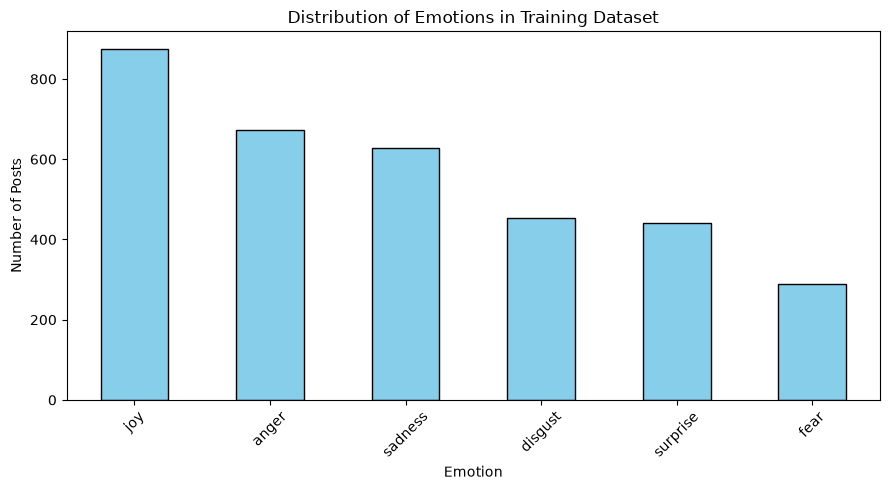


Original vs Cleaned Text:


,text,clean_text,label
0,Thought it looked weird as well.,thought it looked weird as well.,disgust
1,Bear died in a pit,bear died in a pit,disgust
2,I have endured worse.,i have endured worse.,sadness
3,The pottery around Brasov is in danger,the pottery around brasov is in danger,fear
4,"Meanwhile, our soldiers were approaching the a...","meanwhile, our soldiers were approaching the a...",fear
5,"Takes a lot less effort to just say “fuck off,...","takes a lot less effort to just say “fuck off,...",disgust
6,What’s worse is that the judge and businessman...,what’s worse is that the judge and businessman...,disgust
7,Some have now returned to normal life and are ...,some have now returned to normal life and are ...,joy
8,That’s very unfortunate for the bosses. Capita...,that’s very unfortunate for the bosses. capita...,sadness
9,It's sad to see people in the fashion world ne...,it's sad to see people in the fashion world ne...,sadness



FINAL PREPROCESSING RESULTS
---------------------------
Training data shape: (3360, 5)
Testing data shape: (1440, 5)

Preprocessing completed successfully!


In [5]:
### Add the code related to the preprocessing steps in cells inside this section

# ==========================================
# 1. PREPROCESSING STEPS
# ==========================================

# Import required libraries
import os
import json
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ------------------------------------------
# 1.1 Load the dataset
# ------------------------------------------

# Set the dataset directory
kaggle_path = Path(
    "/kaggle/input/competitions/2026-dm-lab-2-private-competition/"
)

if kaggle_path.exists():
    data_path = kaggle_path
else:
    data_path = Path("./data")

# Load CSV files
data_id = pd.read_csv(data_path / "data_identification.csv")
emotion = pd.read_csv(data_path / "emotion.csv")
sample_submission = pd.read_csv(data_path / "sampleSubmission.csv")

# Load JSON file
with open(data_path / "final_posts.json", "r", encoding="utf-8") as f:
    posts = json.load(f)

# Convert JSON data into a DataFrame
posts_df = pd.DataFrame(posts)

print("DATASET INFORMATION")
print("-------------------")
print("Posts shape:", posts_df.shape)
print("Data identification shape:", data_id.shape)
print("Emotion labels shape:", emotion.shape)
print("Sample submission shape:", sample_submission.shape)

display(posts_df.head())
display(data_id.head())
display(emotion.head())


# ------------------------------------------
# 1.2 Merge the datasets
# ------------------------------------------

# First merge: combine text posts with train/test identification
combined_df = pd.merge(
    posts_df,
    data_id,
    on="post_id",
    how="inner",
    validate="one_to_one"
)

# Second merge: add emotion labels
combined_df = pd.merge(
    combined_df,
    emotion,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Separate training and testing datasets
train_df = combined_df[
    combined_df["set"] == "train"
].copy()

test_df = combined_df[
    combined_df["set"] == "test"
].copy()

print("\nMERGED DATASET INFORMATION")
print("--------------------------")
print("Combined dataset:", combined_df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

display(combined_df.head())

# Validate the dataset
assert len(train_df) == 3360
assert len(test_df) == 1440
assert train_df["label"].notna().all()
assert test_df["label"].isna().all()

print("Dataset merging completed successfully!")


# ------------------------------------------
# 1.3 Exploratory Data Analysis
# ------------------------------------------

# Check missing values
print("\nMissing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum())

# Examine emotion class distribution
emotion_counts = train_df["label"].value_counts()

print("\nEmotion distribution:")
print(emotion_counts)

# Visualize emotion distribution
plt.figure(figsize=(9, 5))

emotion_counts.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Emotions in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------
# 1.4 Text Cleaning
# ------------------------------------------

def clean_text(text):

    # Convert input into a string
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Convert text to lowercase
    text = text.lower()

    # Replace URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' URL ',
        text
    )

    # Replace user mentions
    text = re.sub(r'@\w+', ' USER ', text)

    # Remove unnecessary whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply text cleaning
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Compare original and cleaned text
print("\nOriginal vs Cleaned Text:")

display(
    train_df[["text", "clean_text", "label"]].head(10)
)

print("\nFINAL PREPROCESSING RESULTS")
print("---------------------------")
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nPreprocessing completed successfully!")


## 2. Feature Engineering Steps

In [6]:
### Add the code related to the feature engineering steps in cells inside this section
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Define input features and target labels
X = train_df["clean_text"]
y = train_df["label"]

# Split labeled data into 80% training and 20% validation
# Stratification preserves the emotion class distribution

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


# Create word-level TF-IDF features
# Unigrams and bigrams are used to capture words and phrases

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

# Fit the vectorizer using training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation data using the learned vocabulary
X_val_tfidf = tfidf.transform(X_val)

print("Word-level TF-IDF completed successfully!")

print("Training feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)


# Create character-level TF-IDF features
# Character n-grams capture spelling and word patterns

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=30000,
    min_df=2,
    sublinear_tf=True
)

# Fit using training data only
X_train_char = char_tfidf.fit_transform(X_train)

# Transform validation data
X_val_char = char_tfidf.transform(X_val)

print("Character-level TF-IDF completed successfully!")

print("Training feature shape:", X_train_char.shape)
print("Validation feature shape:", X_val_char.shape)


Training samples: 2688
Validation samples: 672
Word-level TF-IDF completed successfully!
Training feature shape: (2688, 6032)
Validation feature shape: (672, 6032)
Character-level TF-IDF completed successfully!
Training feature shape: (2688, 30000)
Validation feature shape: (672, 30000)


## 3. Model Implementation Steps

LINEAR SVM MODEL RESULTS
------------------------
Accuracy: 0.5074
Macro F1 Score: 0.4895
Weighted F1 Score: 0.5064

Classification Report:
              precision    recall  f1-score   support

       anger       0.45      0.46      0.45       135
     disgust       0.33      0.33      0.33        91
        fear       0.56      0.42      0.48        57
         joy       0.59      0.63      0.61       175
     sadness       0.56      0.56      0.56       126
    surprise       0.50      0.50      0.50        88

    accuracy                           0.51       672
   macro avg       0.50      0.48      0.49       672
weighted avg       0.51      0.51      0.51       672



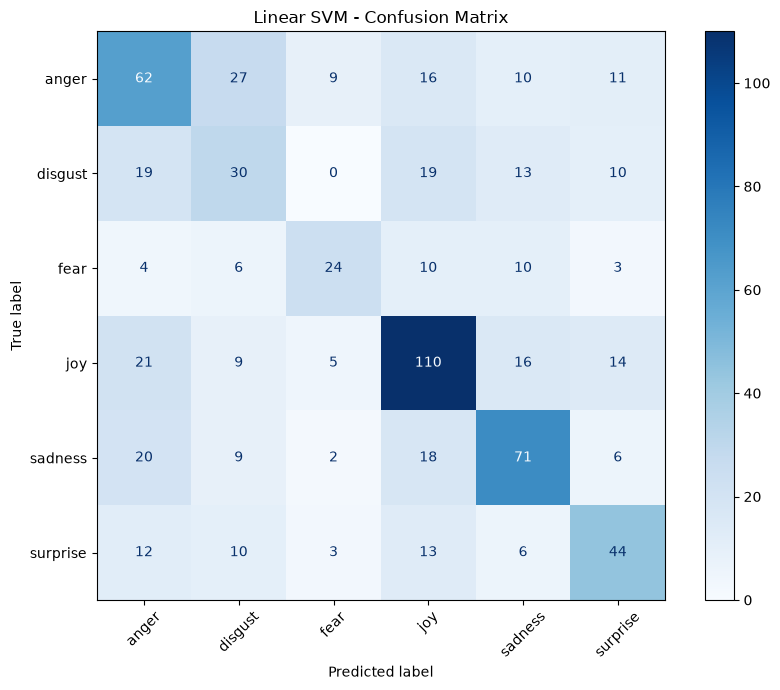

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.5238
Macro F1 Score: 0.5034
Weighted F1 Score: 0.5229

Classification Report:
              precision    recall  f1-score   support

       anger       0.48      0.44      0.46       135
     disgust       0.37      0.38      0.38        91
        fear       0.50      0.42      0.46        57
         joy       0.63      0.65      0.64       175
     sadness       0.56      0.56      0.56       126
    surprise       0.49      0.57      0.53        88

    accuracy                           0.52       672
   macro avg       0.51      0.50      0.50       672
weighted avg       0.52      0.52      0.52       672

CHARACTER TF-IDF + SVM RESULTS
-----------------------------
Accuracy: 0.5223
Macro F1 Score: 0.4981

Classification Report:
              precision    recall  f1-score   support

       anger       0.48      0.47      0.48       135
     disgust       0.37      0.30      0.33        91
        fear       0.54

,C,Macro F1
1,0.10,0.517276
2,0.50,0.504922
3,1.00,0.498065
4,2.00,0.481755
0,0.01,0.472265
5,5.00,0.470268
6,10.00,0.458539


Best C: 0.1
Best Macro F1: 0.5173


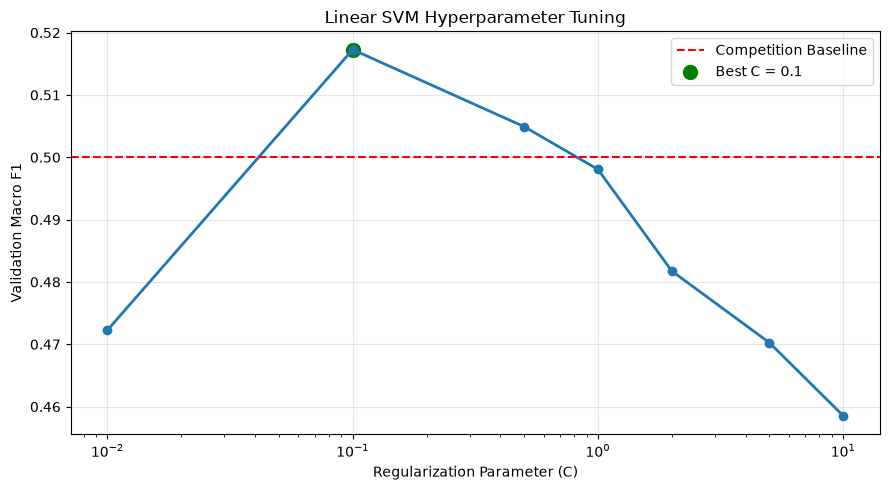

,Model,Macro F1
3,Character TF-IDF + Tuned SVM,0.517276
1,Word TF-IDF + Logistic Regression,0.503406
2,Character TF-IDF + Linear SVM,0.498065
0,Word TF-IDF + Linear SVM,0.489466


Best model: Character TF-IDF + Tuned SVM
Best Macro F1: 0.5173


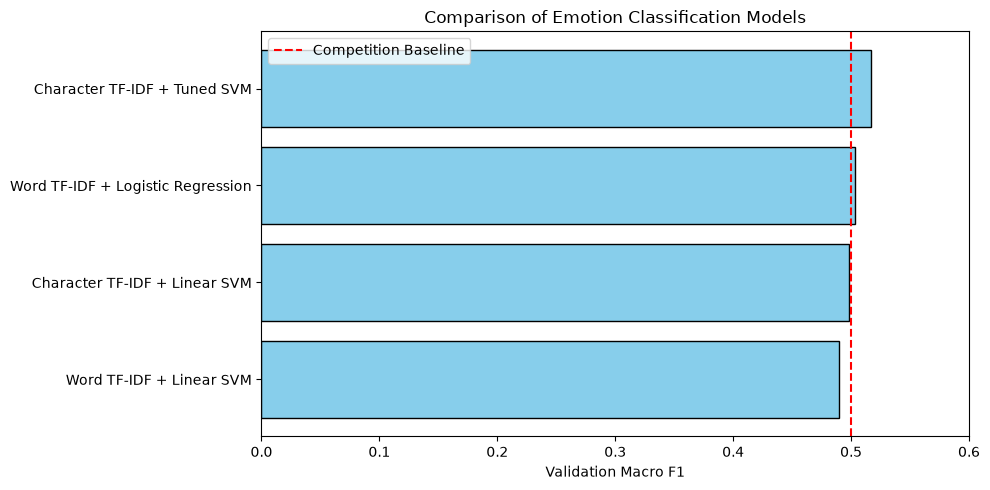

Final model trained successfully!
Training samples: 3360
Test samples: 1440
Number of features: 30000
Total predictions: 1440

Predicted emotion distribution:
joy         440
anger       310
sadness     257
surprise    184
disgust     140
fear        109
Name: count, dtype: int64

First 10 predictions:
['anger' 'fear' 'joy' 'joy' 'surprise' 'disgust' 'surprise' 'joy' 'anger'
 'sadness']


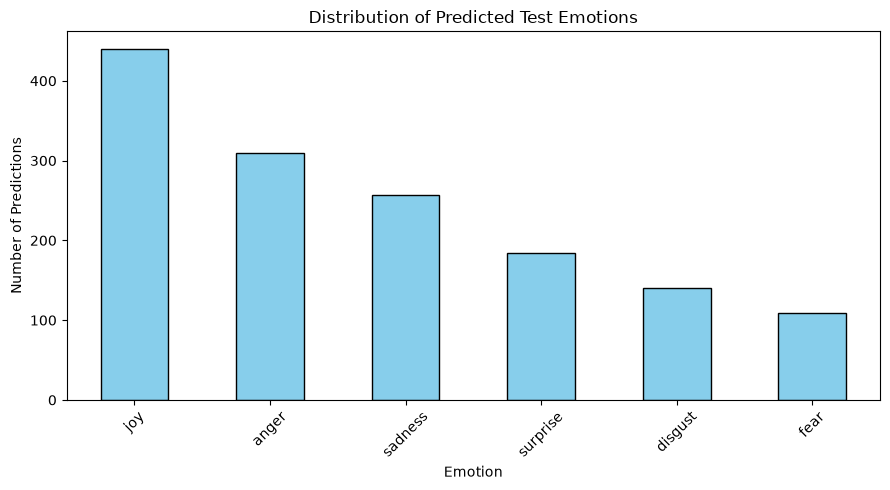

Submission file created successfully!
File location: submission.csv
Columns: ['id', 'label']
Submission shape: (1440, 2)


,id,label
0,xyzx9jp,anger
1,l3vzzxt,fear
2,g680iug,joy
3,m4t8bp6,joy
4,ai3al6e,surprise
5,40acuhg,disgust
6,a7kx7mr,surprise
7,mufm8zo,joy
8,hvpkfa2,anger
9,rwbrblb,sadness


,Evaluation,F1 Score
0,Competition Baseline,0.500000
1,Word TF-IDF + Linear SVM,0.489466
2,Word TF-IDF + Logistic Regression,0.503406
3,Character TF-IDF + Linear SVM,0.498065
4,Character TF-IDF + Tuned SVM,0.517276
5,Kaggle Public Leaderboard,0.522200


Public leaderboard improvement over baseline: 0.0222
Final model: Character TF-IDF + Linear SVM
Selected C value: 0.1
Submission status: Complete


In [7]:
### Add the code related to the model implementation steps in cells inside this section
# Import machine learning algorithms

from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Initialize Linear SVM
# Balanced class weights help address class imbalance

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Predict validation labels
y_val_pred = svm_model.predict(X_val_tfidf)

# Evaluate model performance
accuracy = accuracy_score(y_val, y_val_pred)

macro_f1 = f1_score(
    y_val, y_val_pred, average="macro"
)

weighted_f1 = f1_score(
    y_val, y_val_pred, average="weighted"
)

print("LINEAR SVM MODEL RESULTS")
print("------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Weighted F1 Score: {weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))


# Visualize the classification performance of Linear SVM

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=sorted(y.unique()),
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax
)

plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


# Initialize Logistic Regression

lr_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict validation labels
y_val_pred_lr = lr_model.predict(X_val_tfidf)

# Evaluate model performance
lr_accuracy = accuracy_score(y_val, y_val_pred_lr)

lr_macro_f1 = f1_score(
    y_val, y_val_pred_lr, average="macro"
)

lr_weighted_f1 = f1_score(
    y_val, y_val_pred_lr, average="weighted"
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy: {lr_accuracy:.4f}")
print(f"Macro F1 Score: {lr_macro_f1:.4f}")
print(f"Weighted F1 Score: {lr_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr))


# Train Linear SVM using character-level features

char_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the model
char_svm.fit(X_train_char, y_train)

# Predict validation labels
y_val_pred_char = char_svm.predict(X_val_char)

# Evaluate model performance
char_accuracy = accuracy_score(
    y_val, y_val_pred_char
)

char_macro_f1 = f1_score(
    y_val,
    y_val_pred_char,
    average="macro"
)

print("CHARACTER TF-IDF + SVM RESULTS")
print("-----------------------------")
print(f"Accuracy: {char_accuracy:.4f}")
print(f"Macro F1 Score: {char_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_char))


# Test different regularization parameters for Linear SVM

c_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

tuning_results = []

for c in c_values:

    # Initialize model with the current C value
    model = LinearSVC(
        C=c,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )

    # Train model
    model.fit(X_train_char, y_train)

    # Predict validation labels
    predictions = model.predict(X_val_char)

    # Calculate Macro F1 score
    score = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    # Store experimental results
    tuning_results.append({
        "C": c,
        "Macro F1": score
    })

    print(f"C={c}: Macro F1={score:.4f}")

# Convert results into a DataFrame
tuning_df = pd.DataFrame(tuning_results)

print("\nHyperparameter Tuning Results:")

display(
    tuning_df.sort_values(
        by="Macro F1",
        ascending=False
    )
)

# Select the best regularization parameter
best_c = tuning_df.loc[
    tuning_df["Macro F1"].idxmax(), "C"
]

best_char_f1 = tuning_df["Macro F1"].max()

print("Best C:", best_c)
print("Best Macro F1:", round(best_char_f1, 4))


# Visualize the relationship between C and Macro F1

plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df["C"],
    tuning_df["Macro F1"],
    marker="o",
    linewidth=2
)

# Display C values on a logarithmic scale
plt.xscale("log")

# Display competition baseline
plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Competition Baseline"
)

# Highlight the best parameter
plt.scatter(
    best_c,
    best_char_f1,
    color="green",
    s=100,
    label=f"Best C = {best_c}"
)

plt.title("Linear SVM Hyperparameter Tuning")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Compare the performance of all implemented models

comparison = pd.DataFrame({
    "Model": [
        "Word TF-IDF + Linear SVM",
        "Word TF-IDF + Logistic Regression",
        "Character TF-IDF + Linear SVM",
        "Character TF-IDF + Tuned SVM"
    ],
    "Macro F1": [
        macro_f1,
        lr_macro_f1,
        char_macro_f1,
        best_char_f1
    ]
})

# Sort models according to Macro F1 score
comparison = comparison.sort_values(
    by="Macro F1",
    ascending=False
)

display(comparison)

print("Best model:", comparison.iloc[0]["Model"])

print(
    "Best Macro F1:",
    round(comparison.iloc[0]["Macro F1"], 4)
)

# Visualize model comparison
plt.figure(figsize=(10, 5))

plt.barh(
    comparison["Model"],
    comparison["Macro F1"],
    color="skyblue",
    edgecolor="black"
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    label="Competition Baseline"
)

plt.xlabel("Validation Macro F1")
plt.title("Comparison of Emotion Classification Models")
plt.xlim(0, 0.6)
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()


# Train the selected model using all labeled training data

final_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=30000,
    min_df=2,
    sublinear_tf=True
)

# Extract features from all labeled posts
X_full = final_tfidf.fit_transform(
    train_df["clean_text"]
)

y_full = train_df["label"]

# Transform competition test data
X_test_final = final_tfidf.transform(
    test_df["clean_text"]
)

# Initialize the final model using the selected C value
# C = 0.1 achieved the best validation performance

final_model = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the final model
final_model.fit(X_full, y_full)

print("Final model trained successfully!")
print("Training samples:", X_full.shape[0])
print("Test samples:", X_test_final.shape[0])
print("Number of features:", X_full.shape[1])


# Predict emotions for all competition test posts

test_predictions = final_model.predict(X_test_final)

print("Total predictions:", len(test_predictions))

# Examine the predicted emotion distribution
prediction_counts = pd.Series(
    test_predictions
).value_counts()

print("\nPredicted emotion distribution:")
print(prediction_counts)

print("\nFirst 10 predictions:")
print(test_predictions[:10])

# Visualize the predicted emotion distribution
plt.figure(figsize=(9, 5))

prediction_counts.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Predicted Test Emotions")
plt.xlabel("Emotion")
plt.ylabel("Number of Predictions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Create the final Kaggle submission DataFrame

prediction_df = pd.DataFrame({
    "post_id": test_df["post_id"].values,
    "label": test_predictions
})

# Preserve the original sample submission ID order
submission = sample_submission[["post_id"]].merge(
    prediction_df,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Rename post_id to id as required by Kaggle
submission = submission.rename(
    columns={"post_id": "id"}
)

# Ensure the correct column order
submission = submission[["id", "label"]]

# Ensure both columns contain string values
submission = submission.astype({
    "id": str,
    "label": str
})

# Validate submission format
assert submission.shape == (1440, 2)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].is_unique
assert submission.notna().all().all()

# Verify the ID order
assert submission["id"].tolist() == (
    sample_submission["post_id"].astype(str).tolist()
)

# Verify that all predicted labels are valid
assert set(submission["label"]).issubset(
    set(train_df["label"])
)

# Select the output directory
if Path("/kaggle/working").exists():
    output_path = Path("/kaggle/working/submission.csv")
else:
    output_path = Path("./submission.csv")

# Save the submission CSV
submission.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

# Verify the saved CSV file
saved_submission = pd.read_csv(output_path, dtype=str)

assert saved_submission.columns.tolist() == ["id", "label"]
assert saved_submission.shape == (1440, 2)
assert saved_submission.notna().all().all()

print("Submission file created successfully!")
print("File location:", output_path)
print("Columns:", saved_submission.columns.tolist())
print("Submission shape:", saved_submission.shape)

display(saved_submission.head(10))


# Summarize validation and Kaggle competition results

# Public leaderboard score obtained from Kaggle
# Version 3 was marked complete after the deadline

competition_baseline = 0.5000
kaggle_public_score = 0.5222

final_results = pd.DataFrame({
    "Evaluation": [
        "Competition Baseline",
        "Word TF-IDF + Linear SVM",
        "Word TF-IDF + Logistic Regression",
        "Character TF-IDF + Linear SVM",
        "Character TF-IDF + Tuned SVM",
        "Kaggle Public Leaderboard"
    ],
    "F1 Score": [
        competition_baseline,
        macro_f1,
        lr_macro_f1,
        char_macro_f1,
        best_char_f1,
        kaggle_public_score
    ]
})

display(final_results)

print(
    "Public leaderboard improvement over baseline:",
    round(kaggle_public_score - competition_baseline, 4)
)

print("Final model: Character TF-IDF + Linear SVM")
print("Selected C value: 0.1")
print("Submission status: Complete")
